**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


In [19]:
job_names = ["net_v3_0per", "net_v3_20per", "net_v3_40per", "net_v3_60per", "net_v3_80per"]

def load_job(job_name):
    results_dir = f"/tmp/anomaly_results_ocsvm_{job_name}"         
    shutil.rmtree(results_dir, ignore_errors=True)
    zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download(f"{results_dir}.zip", overwrite=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(results_dir)
    with open(f"{results_dir}/anomaly_results.json") as f:
        results = json.load(f)
    df = pd.read_csv(f"{results_dir}/scores.csv")
    return results, df

summary = []        
all_rules = {}      

for job_name in job_names:
    results, df = load_job(job_name)
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    summary.append({
        "job_name": job_name,
        "min_flood_area": results["min_flood_area"],
        "nu": results['ocsvm']['nu'], "gamma": results['ocsvm']['gamma'], "dim": results['ocsvm']['dim'], "frac_out": results['ocsvm']['frac_outside_fit'],
        "n_fit": results["n_fit"], "n_normali": results["n_normali"], "n_anomale": results["n_anomale"],
        "score_normali": f"{score_normal.mean():.4f} ± {score_normal.std():.4f}",
        "score_anomale": f"{score_anom.mean():.4f} ± {score_anom.std():.4f}",
        "auroc": results["auroc"],
    })
    all_rules[job_name] = pd.DataFrame(results["rules"]).T

df_summary = pd.DataFrame(summary).set_index("job_name")
df_rules = pd.concat(all_rules, names=["job_name", "regola"])     

df_summary

,min_flood_area,nu,gamma,dim,frac_out,n_fit,n_normali,n_anomale,score_normali,score_anomale,auroc
job_name,,,,,,,,,,,
net_v3_0per,0.0,0.05,scale,256,0.060653,2572,2402,2402,1.5428 ± 1.0951,0.9243 ± 1.0018,0.658010
net_v3_20per,20.0,0.05,scale,256,0.058320,2572,1085,1085,1.5624 ± 1.0854,0.8149 ± 0.9173,0.697822
net_v3_40per,40.0,0.05,scale,256,0.058320,2572,642,642,1.5381 ± 1.0945,0.8062 ± 0.8630,0.695835
net_v3_60per,60.0,0.05,scale,256,0.058320,2572,359,359,1.5210 ± 1.0961,0.8591 ± 0.8648,0.680426
net_v3_80per,80.0,0.05,scale,256,0.058320,2572,173,173,1.6163 ± 1.0784,0.9622 ± 0.9079,0.677036


In [20]:
df_rules

,,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
job_name,regola,,,,,,,,,,
net_v3_0per,ocsvm score < 0,0.0,453.0,212.0,1949.0,2190.0,0.088260,0.811407,0.188593,0.681203,0.295403
net_v3_20per,ocsvm score < 0,0.0,209.0,93.0,876.0,992.0,0.085714,0.807373,0.192627,0.692053,0.301370
net_v3_40per,ocsvm score < 0,0.0,112.0,57.0,530.0,585.0,0.088785,0.825545,0.174455,0.662722,0.276202
net_v3_60per,ocsvm score < 0,0.0,60.0,35.0,299.0,324.0,0.097493,0.832869,0.167131,0.631579,0.264317
net_v3_80per,ocsvm score < 0,0.0,23.0,14.0,150.0,159.0,0.080925,0.867052,0.132948,0.621622,0.219048


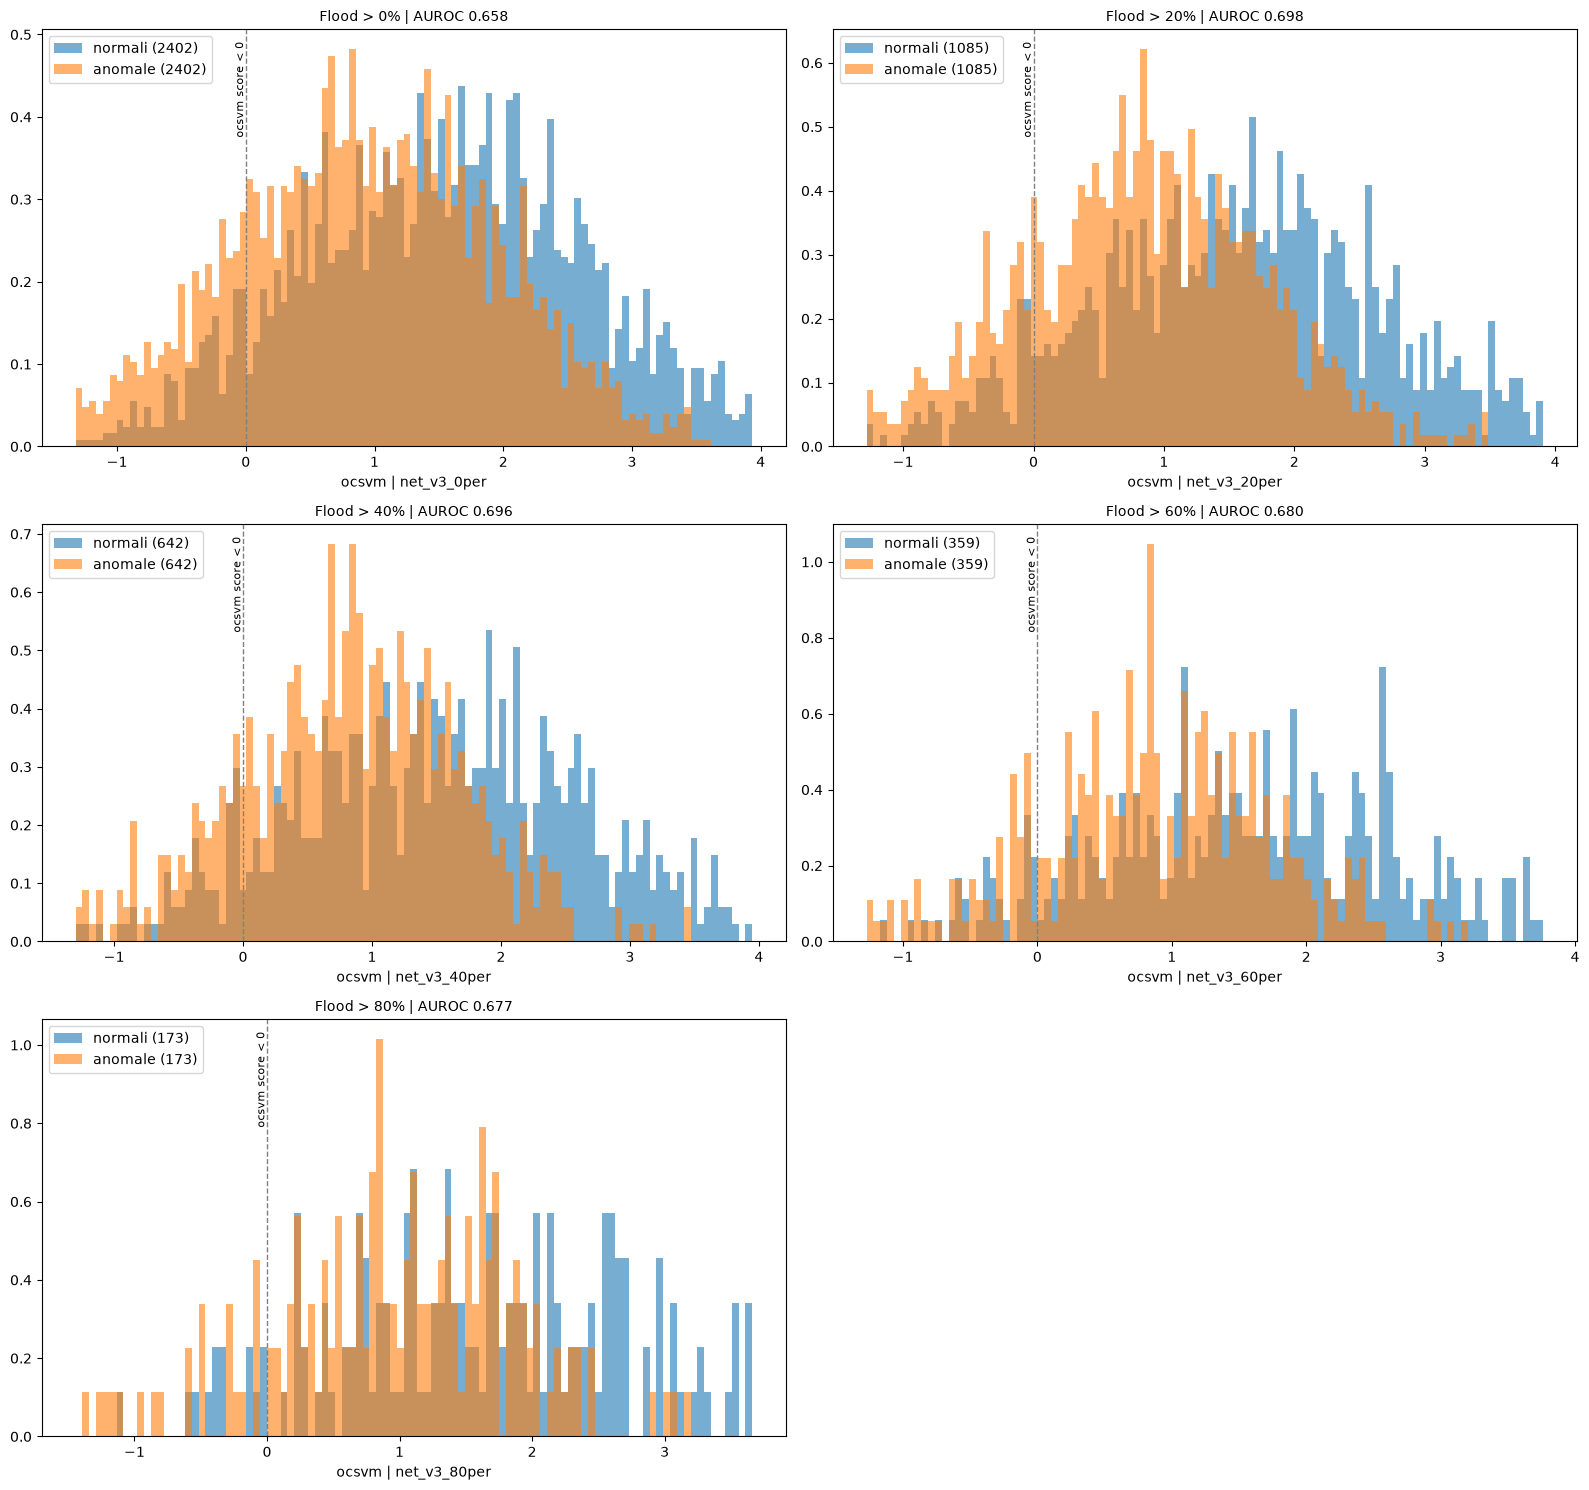

In [21]:
def plot_hist(ax, job_name, results, df):
    score_normal = df[df.label == 0]["score"]
    score_anom = df[df.label == 1]["score"]

    lo, hi = np.quantile(df.score, [0.005, 0.995])               
    bins = np.linspace(lo, hi, 100)

    ax.hist(score_normal, bins=bins, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
    ax.hist(score_anom, bins=bins, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
    for nome, r in results["rules"].items():                     
        if lo <= r["soglia"] <= hi:
            ax.axvline(x=r["soglia"], color="gray", linestyle="--", linewidth=1)
            ax.text(r["soglia"], ax.get_ylim()[1] * 0.97, nome.split("(")[-1].rstrip(")"),
                    rotation=90, va="top", ha="right", fontsize=8)
    ax.set_xlabel(f"ocsvm | {job_name}")
    ax.legend(loc="upper left")
    ax.set_title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=10)


n_cols = 2
n_rows = int(np.ceil(len(job_names) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 5 * n_rows), squeeze=False)

for ax, job_name in zip(axes.flat, job_names):
    results, df = load_job(job_name)
    plot_hist(ax, job_name, results, df)

for ax in axes.flat[len(job_names):]:                           
    ax.axis("off")

plt.tight_layout()
plt.show()

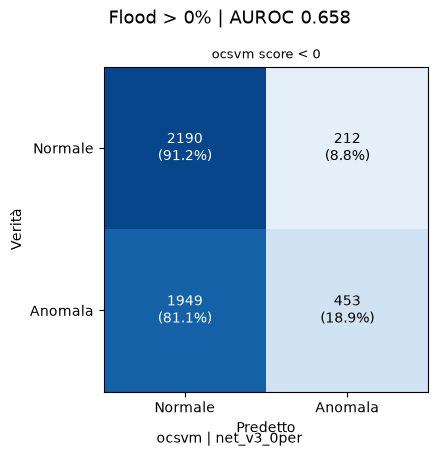

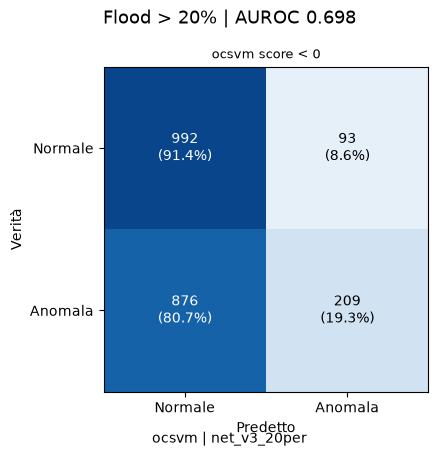

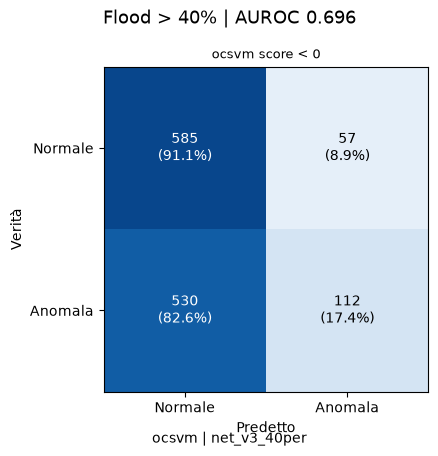

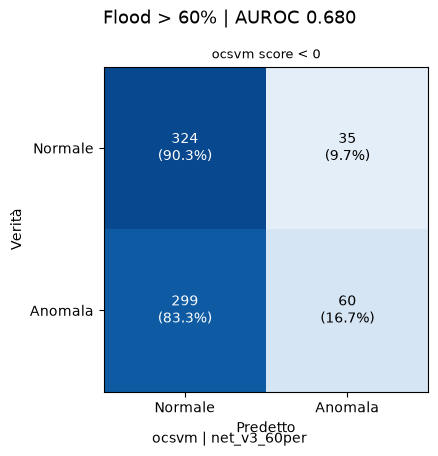

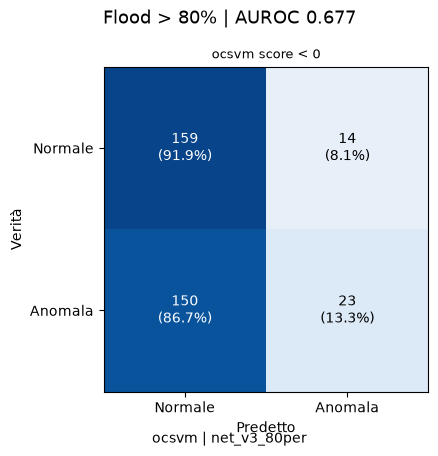

In [22]:
def plot_confusion(job_name, results):
    rules = results["rules"]
    fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

    for ax, (nome, r) in zip(axes[0], rules.items()):
        mat = np.array([[r["TN"], r["FP"]],
                        [r["FN"], r["TP"]]])
        mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

        ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
        ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
        ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
        ax.set_title(nome, fontsize=9)

        for i in range(2):
            for j in range(2):
                color = "white" if mat_pct[i, j] > 55 else "black"
                ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                        ha="center", va="center", color=color, fontsize=10)

    fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
    fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)
    plt.tight_layout()
    plt.show()


for job_name in job_names:
    results, df = load_job(job_name)
    plot_confusion(job_name, results)